In [ ]:
!pip install -q xgboost scikit-survival

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.4/142.4 kB 1.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 59.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from xgboost import XGBClassifier

from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sksurv.metrics import concordance_index_censored

pd.set_option("display.max_columns", None)

In [ ]:
df = pd.read_csv("dataset telkom.csv", sep=";")

# Rapikan nama kolom dan spasi pada data teks
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Ukuran dataset:", df.shape)
display(df.head())

print("\nInformasi kolom:")
df.info()

Ukuran dataset: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

# Cleaning

In [ ]:
df_clean = df.copy()

# Rapikan spasi pada data kategorikal
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

# Ubah TotalCharges menjadi numerik
if "TotalCharges" in df_clean.columns:
    df_clean["TotalCharges"] = pd.to_numeric(
        df_clean["TotalCharges"],
        errors="coerce"
    )

print("SETELAH PEMBERSIHAN FORMAT")
print("\nUkuran data:", df_clean.shape)

print("\nTipe data setelah perubahan:")
print(df_clean.dtypes)

SETELAH PEMBERSIHAN FORMAT

Ukuran data: (7043, 21)

Tipe data setelah perubahan:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [ ]:
missing_summary = pd.DataFrame({
    "Jumlah Missing": df_clean.isna().sum(),
    "Persentase Missing (%)": (
        df_clean.isna().mean() * 100
    ).round(2)
})

print("MISSING VALUE")
display(
    missing_summary[
        missing_summary["Jumlah Missing"] > 0
    ].sort_values("Jumlah Missing", ascending=False)
)

print("Total seluruh missing value:",
      df_clean.isna().sum().sum())

MISSING VALUE


,Jumlah Missing,Persentase Missing (%)
TotalCharges,11,0.16


Total seluruh missing value: 11


In [ ]:
print("Jumlah seluruh baris:", len(df_clean))
print("Jumlah baris duplikat:", df_clean.duplicated().sum())

if "customerID" in df_clean.columns:
    print(
        "Jumlah customerID duplikat:",
        df_clean["customerID"].duplicated().sum()
    )

Jumlah seluruh baris: 7043
Jumlah baris duplikat: 0
Jumlah customerID duplikat: 0


In [ ]:
print("DISTRIBUSI TARGET CHURN")

display(
    df_clean["Churn"]
    .value_counts(dropna=False)
    .rename_axis("Status Churn")
    .to_frame("Jumlah")
)

display(
    (df_clean["Churn"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("Persentase (%)")
    .to_frame()
)

DISTRIBUSI TARGET CHURN


,Jumlah
Status Churn,
No,5174
Yes,1869


,Persentase (%)
Churn,
No,73.46
Yes,26.54


In [ ]:
print("FILTER TARGET DAN DURASI")
print("Jumlah baris:", len(df_clean))

print("Churn kosong:", df_clean["Churn"].isna().sum())
print("Tenure kosong:", df_clean["tenure"].isna().sum())

# Pastikan tenure berupa numerik
df_clean["tenure"] = pd.to_numeric(
    df_clean["tenure"], errors="coerce"
)

df_clean = df_clean.dropna(
    subset=["Churn", "tenure"]
).copy()

# Pertahankan label yang valid
df_clean["Churn"] = df_clean["Churn"].astype(str).str.strip()
df_clean = df_clean[
    df_clean["Churn"].isin(["Yes", "No"])
].copy()

print("\nSETELAH FILTER")
print("Ukuran data:", df_clean.shape)
print("Missing Churn:", df_clean["Churn"].isna().sum())
print("Missing tenure:", df_clean["tenure"].isna().sum())

display(df_clean.head())

FILTER TARGET DAN DURASI
Jumlah baris: 7043
Churn kosong: 0
Tenure kosong: 0

SETELAH FILTER
Ukuran data: (7043, 21)
Missing Churn: 0
Missing tenure: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
from sklearn.model_selection import train_test_split

# Target klasifikasi: Yes = 1, No = 0
y = (df_clean["Churn"] == "Yes").astype(int)

# --- Split 80/20 dulu: train_full + test ---
train_full_df, test_df = train_test_split(
    df_clean,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# --- Split train_full jadi train (80%) + val (20%) ---
y_train_full = (train_full_df["Churn"] == "Yes").astype(int)
train_df, val_df = train_test_split(
    train_full_df,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

y_train = (train_df["Churn"] == "Yes").astype(int)
y_val   = (val_df["Churn"] == "Yes").astype(int)
y_test  = (test_df["Churn"] == "Yes").astype(int)

print("HASIL PEMBAGIAN DATA 3-WAY")
print(f"train_full : {len(train_full_df)}")
print(f"train      : {len(train_df)}   (churn={y_train.mean():.3f})")
print(f"val        : {len(val_df)}     (churn={y_val.mean():.3f})")
print(f"test       : {len(test_df)}    (churn={y_test.mean():.3f})")

HASIL PEMBAGIAN DATA 3-WAY
train_full : 5634
train      : 4507   (churn=0.265)
val        : 1127     (churn=0.265)
test       : 1409    (churn=0.265)


# Preprocessing

In [ ]:
# XGBoost: keluarkan ID dan target
X_train_xgb_raw = train_df.drop(columns=["customerID", "Churn"], errors="ignore").copy()
X_val_xgb_raw   = val_df.drop(columns=["customerID", "Churn"], errors="ignore").copy()
X_test_xgb_raw  = test_df.drop(columns=["customerID", "Churn"], errors="ignore").copy()

# RSF: keluarkan ID, target, durasi, dan TotalCharges
# TotalCharges dikeluarkan karena sangat berkaitan dengan tenure
drop_rsf = ["customerID", "Churn", "tenure", "TotalCharges"]
X_train_rsf_raw = train_df.drop(columns=drop_rsf, errors="ignore").copy()
X_val_rsf_raw   = val_df.drop(columns=drop_rsf, errors="ignore").copy()
X_test_rsf_raw  = test_df.drop(columns=drop_rsf, errors="ignore").copy()

print("XGBoost train / val / test :", X_train_xgb_raw.shape, X_val_xgb_raw.shape, X_test_xgb_raw.shape)
print("RSF     train / val / test :", X_train_rsf_raw.shape, X_val_rsf_raw.shape, X_test_rsf_raw.shape)

XGBoost train / val / test : (4507, 19) (1127, 19) (1409, 19)
RSF     train / val / test : (4507, 17) (1127, 17) (1409, 17)


In [ ]:
def tampilkan_tipe_fitur(X, nama_model):
    numeric_cols = X.select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical_cols = [
        col for col in X.columns
        if col not in numeric_cols
    ]

    print(f"\nTIPE FITUR {nama_model}")
    print("Kolom numerik:", numeric_cols)
    print("Jumlah kolom numerik:", len(numeric_cols))

    print("\nKolom kategorikal:", categorical_cols)
    print("Jumlah kolom kategorikal:", len(categorical_cols))

    return numeric_cols, categorical_cols


num_xgb, cat_xgb = tampilkan_tipe_fitur(
    X_train_xgb_raw, "XGBOOST"
)

num_rsf, cat_rsf = tampilkan_tipe_fitur(
    X_train_rsf_raw, "RSF"
)


TIPE FITUR XGBOOST
Kolom numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Jumlah kolom numerik: 4

Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Jumlah kolom kategorikal: 15

TIPE FITUR RSF
Kolom numerik: ['SeniorCitizen', 'MonthlyCharges']
Jumlah kolom numerik: 2

Kolom kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Jumlah kolom kategorikal: 15


**Pre-processig data training XGB**


In [ ]:
def preprocess_features(X_train_raw, X_val_raw, X_test_raw, nama_model):
    """Impute + encode. Statistik (median, kategori) fit dari TRAIN saja."""
    X_train = X_train_raw.copy()
    X_val   = X_val_raw.copy()
    X_test  = X_test_raw.copy()

    # Tahap 1: identifikasi tipe kolom
    numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

    print(f"\nPREPROCESSING {nama_model}")
    print("Numerik:", numeric_cols)
    print("Kategorikal:", categorical_cols)

    # Tahap 2: missing value sebelum imputasi
    missing_before = pd.DataFrame({
        "Train": X_train.isna().sum(),
        "Val":   X_val.isna().sum(),
        "Test":  X_test.isna().sum(),
    })
    print("\nMissing sebelum imputasi:")
    display(missing_before[(missing_before.sum(axis=1) > 0)])

    # Tahap 3: imputasi numerik (median dari TRAIN)
    for col in numeric_cols:
        med = X_train[col].median()
        X_train[col] = X_train[col].fillna(med)
        X_val[col]   = X_val[col].fillna(med)
        X_test[col]  = X_test[col].fillna(med)

    # Tahap 4: imputasi kategorikal
    for col in categorical_cols:
        X_train[col] = X_train[col].fillna("Unknown")
        X_val[col]   = X_val[col].fillna("Unknown")
        X_test[col]  = X_test[col].fillna("Unknown")

    # Tahap 5: one-hot encoding
    X_train = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
    X_val   = pd.get_dummies(X_val,   columns=categorical_cols, dtype=int)
    X_test  = pd.get_dummies(X_test,  columns=categorical_cols, dtype=int)

    # Tahap 6: penyelarasan kolom (val & test mengikuti train)
    X_val  = X_val.reindex(columns=X_train.columns, fill_value=0)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    print(f"Bentuk akhir: train={X_train.shape}  val={X_val.shape}  test={X_test.shape}")
    print("Missing:", X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())
    print("Kolom train==val==test:",
          X_train.columns.equals(X_val.columns) and X_train.columns.equals(X_test.columns))

    return X_train, X_val, X_test

In [ ]:
X_train_xgb, X_val_xgb, X_test_xgb = preprocess_features(
    X_train_xgb_raw,
    X_val_xgb_raw,
    X_test_xgb_raw,
    "XGBOOST"
)


PREPROCESSING XGBOOST
Numerik: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Missing sebelum imputasi:


,Train,Val,Test
TotalCharges,7,1,3


Bentuk akhir: train=(4507, 45)  val=(1127, 45)  test=(1409, 45)
Missing: 0 0 0
Kolom train==val==test: True


**Pre-Processing data training RSF**

In [ ]:
X_train_rsf, X_val_rsf, X_test_rsf = preprocess_features(
    X_train_rsf_raw,
    X_val_rsf_raw,
    X_test_rsf_raw,
    "RANDOM SURVIVAL FOREST"
)


PREPROCESSING RANDOM SURVIVAL FOREST
Numerik: ['SeniorCitizen', 'MonthlyCharges']
Kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Missing sebelum imputasi:


,Train,Val,Test


Bentuk akhir: train=(4507, 43)  val=(1127, 43)  test=(1409, 43)
Missing: 0 0 0
Kolom train==val==test: True


In [ ]:
event_train = (train_df["Churn"] == "Yes").to_numpy()
event_val   = (val_df["Churn"]   == "Yes").to_numpy()
event_test  = (test_df["Churn"]  == "Yes").to_numpy()

time_train = train_df["tenure"].to_numpy(dtype=float)
time_val   = val_df["tenure"].to_numpy(dtype=float)
time_test  = test_df["tenure"].to_numpy(dtype=float)

y_train_surv = Surv.from_arrays(event=event_train, time=time_train)
y_val_surv   = Surv.from_arrays(event=event_val,   time=time_val)
y_test_surv  = Surv.from_arrays(event=event_test,  time=time_test)

print("TARGET SURVIVAL RSF")
print("Train  — event:", event_train.sum(), "| censored:", (~event_train).sum())
print("Val    — event:", event_val.sum(),   "| censored:", (~event_val).sum())
print("Test   — event:", event_test.sum(),  "| censored:", (~event_test).sum())

TARGET SURVIVAL RSF
Train  — event: 1196 | censored: 3311
Val    — event: 299 | censored: 828
Test   — event: 374 | censored: 1035


#XGB

In [ ]:
%%time
# ==========================================================
# FIX 1 — GridSearch dengan scoring=average_precision
# ==========================================================
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import pandas as pd

scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (teoretis) = {scale_pos:.4f}")

param_grid = {
    "n_estimators"    : [300, 500],
    "max_depth"       : [3, 4, 5],
    "learning_rate"   : [0.03, 0.05],
    "scale_pos_weight": [1.0, float(scale_pos), 4.0],
}

grid = GridSearchCV(
    estimator=XGBClassifier(
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",   # ← HARUS binary:logistic
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
    ),
    param_grid=param_grid,
    scoring="average_precision",       # ← ini yang diubah (PR-AUC)
    cv=5,
    n_jobs=-1,
    verbose=2,
    return_train_score=True,
)

grid.fit(X_train_xgb, y_train)

# ---------- Hasil ----------
print("\n" + "=" * 60)
print("HASIL GRIDSEARCH (scoring = PR-AUC)")
print("=" * 60)
print("Best params     :", grid.best_params_)
print(f"Best CV PR-AUC  : {grid.best_score_:.4f}")

cv_df = pd.DataFrame(grid.cv_results_)
top5 = (
    cv_df[["params", "mean_test_score", "std_test_score"]]
    .sort_values("mean_test_score", ascending=False)
    .head(5)
    .reset_index(drop=True)
)
top5["mean_test_score"] = top5["mean_test_score"].round(4)
top5["std_test_score"]  = top5["std_test_score"].round(4)
print("\nTop-5 kombinasi:")
display(top5)

xgb_model = grid.best_estimator_
xgb_pred  = xgb_model.predict(X_test_xgb)
xgb_prob  = xgb_model.predict_proba(X_test_xgb)[:, 1]

# Prediksi VAL (untuk tuning threshold, bobot fusion, dll.)
xgb_prob_val = xgb_model.predict_proba(X_val_xgb)[:, 1]

from sklearn.metrics import average_precision_score
print(f"\nVAL  ROC-AUC       : {roc_auc_score(y_val, xgb_prob_val):.4f}")
print(f"VAL  PR-AUC        : {average_precision_score(y_val, xgb_prob_val):.4f}")
print(f"TEST ROC-AUC       : {roc_auc_score(y_test, xgb_prob):.4f}")
print(f"TEST PR-AUC        : {average_precision_score(y_test, xgb_prob):.4f}")

scale_pos_weight (teoretis) = 2.7684
Fitting 5 folds for each of 36 candidates, totalling 180 fits

HASIL GRIDSEARCH (scoring = PR-AUC)
Best params     : {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'scale_pos_weight': 4.0}
Best CV PR-AUC  : 0.6673

Top-5 kombinasi:


,params,mean_test_score,std_test_score
0,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.6673,0.0085
1,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.6668,0.0097
2,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.6658,0.0114
3,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.6653,0.0076
4,"{'learning_rate': 0.03, 'max_depth': 3, 'n_est...",0.6645,0.0066



VAL  ROC-AUC       : 0.8527
VAL  PR-AUC        : 0.6757
TEST ROC-AUC       : 0.8447
TEST PR-AUC        : 0.6610
CPU times: user 1.37 s, sys: 135 ms, total: 1.51 s
Wall time: 52.8 s


Accuracy : 0.8076650106458482
Precision: 0.6745762711864407
Recall   : 0.5320855614973262
F1-score : 0.5949177877428998
ROC-AUC  : 0.8482755948229093

Classification report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



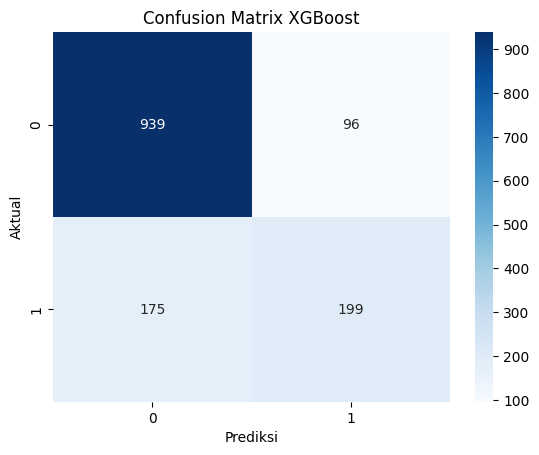

In [ ]:
print("Accuracy :", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred, zero_division=0))
print("Recall   :", recall_score(y_test, xgb_pred, zero_division=0))
print("F1-score :", f1_score(y_test, xgb_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, xgb_prob))

print("\nClassification report:")
print(classification_report(
    y_test,
    xgb_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

cm = confusion_matrix(y_test, xgb_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix XGBoost")
plt.show()

In [ ]:
# EKSPERIMEN IMBALANCE: scale_pos_weight vs SMOTE
!pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE
from sklearn.metrics import average_precision_score

# --- Strategi A: scale_pos_weight (sudah dari grid.best_params_) ---
pr_weighted_val = average_precision_score(y_val, xgb_prob_val)
print(f"[A] scale_pos_weight={grid.best_params_['scale_pos_weight']:.2f}  → VAL PR-AUC = {pr_weighted_val:.4f}")

# --- Strategi B: SMOTE ---
X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train_xgb, y_train)
print(f"\n[SMOTE] distribusi kelas train:")
print(f"  sebelum: {y_train.value_counts().to_dict()}")
print(f"  sesudah: {pd.Series(y_train_sm).value_counts().to_dict()}")

# Pakai hyperparameter sama kecuali scale_pos_weight (SMOTE sudah seimbangkan)
best_params_no_w = {k: v for k, v in grid.best_params_.items() if k != "scale_pos_weight"}
xgb_smote = XGBClassifier(
    **best_params_no_w,
    subsample=0.8, colsample_bytree=0.8,
    objective="binary:logistic", eval_metric="logloss",
    random_state=42, n_jobs=-1,
)
xgb_smote.fit(X_train_sm, y_train_sm)

xgb_smote_prob_val  = xgb_smote.predict_proba(X_val_xgb)[:, 1]
xgb_smote_prob_test = xgb_smote.predict_proba(X_test_xgb)[:, 1]
pr_smote_val = average_precision_score(y_val, xgb_smote_prob_val)
print(f"[B] SMOTE                → VAL PR-AUC = {pr_smote_val:.4f}")

# --- Pilih strategi berdasarkan VAL ---
if pr_smote_val > pr_weighted_val:
    xgb_prob_val = xgb_smote_prob_val
    xgb_prob     = xgb_smote_prob_test
    xgb_strategy = f"SMOTE (VAL PR-AUC={pr_smote_val:.4f})"
else:
    xgb_strategy = f"scale_pos_weight={grid.best_params_['scale_pos_weight']} (VAL PR-AUC={pr_weighted_val:.4f})"

print(f"\n→ Strategi terpilih: {xgb_strategy}")

[A] scale_pos_weight=4.00  → VAL PR-AUC = 0.6757

[SMOTE] distribusi kelas train:
  sebelum: {0: 3311, 1: 1196}
  sesudah: {0: 3311, 1: 3311}
[B] SMOTE                → VAL PR-AUC = 0.6506

→ Strategi terpilih: scale_pos_weight=4.0 (VAL PR-AUC=0.6757)


In [ ]:
# THRESHOLD TUNING — pada VALIDATION (val global, bukan split baru)
from sklearn.metrics import precision_recall_curve
import numpy as np

# Pakai xgb_prob_val dari Patch 7 (model final di-fit di seluruh train)
# dan y_val dari Patch 1 (val global)
prec_v, rec_v, thr_v = precision_recall_curve(y_val, xgb_prob_val)
f1s_v = 2 * prec_v * rec_v / (prec_v + rec_v + 1e-9)
best_thr_val = thr_v[np.argmax(f1s_v[:-1])]

print(f"→ Threshold optimal dari VALIDATION: {best_thr_val:.4f}")
print(f"→ F1 pada validation              : {f1s_v.max():.4f}")
print(f"→ Jumlah data val yang dipakai    : {len(y_val)}")

→ Threshold optimal dari VALIDATION: 0.7062
→ F1 pada validation              : 0.6646
→ Jumlah data val yang dipakai    : 1127


In [ ]:
# Membuat tabel hasil prediksi XGBoost
hasil_xgb = pd.DataFrame({
    "customerID": test_df["customerID"].values,
    "Churn_Aktual": y_test.values,
    "Probabilitas_Churn": xgb_prob,
    "Prediksi_Churn": xgb_pred
})

# Mengubah label angka menjadi teks
hasil_xgb["Churn_Aktual"] = hasil_xgb["Churn_Aktual"].map({
    0: "No Churn",
    1: "Churn"
})

hasil_xgb["Prediksi_Churn"] = hasil_xgb["Prediksi_Churn"].map({
    0: "No Churn",
    1: "Churn"
})

# Menambahkan status benar atau salah
hasil_xgb["Hasil_Prediksi"] = np.where(
    hasil_xgb["Churn_Aktual"] == hasil_xgb["Prediksi_Churn"],
    "Benar",
    "Salah"
)

# Menampilkan hasil
display(hasil_xgb.head(20))

,customerID,Churn_Aktual,Probabilitas_Churn,Prediksi_Churn,Hasil_Prediksi
0,4376-KFVRS,No Churn,0.021587,No Churn,Benar
1,2754-SDJRD,No Churn,0.813965,Churn,Salah
2,9917-KWRBE,No Churn,0.070134,No Churn,Benar
3,0365-GXEZS,No Churn,0.318870,No Churn,Benar
4,9385-NXKDA,No Churn,0.014322,No Churn,Benar
5,4686-UXDML,No Churn,0.614674,Churn,Salah
6,2227-JRSJX,No Churn,0.456340,No Churn,Benar
7,4830-FAXFM,No Churn,0.107339,No Churn,Benar
8,1830-IPXVJ,No Churn,0.010975,No Churn,Benar
9,4690-LLKUA,Churn,0.351239,No Churn,Salah


#RSF

In [ ]:
# Event = True apabila churn
event_train = (train_df["Churn"] == "Yes").to_numpy()
event_test = (test_df["Churn"] == "Yes").to_numpy()

# Waktu dalam bulan
time_train = train_df["tenure"].to_numpy(dtype=float)
time_test = test_df["tenure"].to_numpy(dtype=float)

# Bentuk target survival
y_train_surv = Surv.from_arrays(
    event=event_train,
    time=time_train
)

y_test_surv = Surv.from_arrays(
    event=event_test,
    time=time_test
)

rsf_model = RandomSurvivalForest(
    n_estimators=300,
    min_samples_split=10,
    min_samples_leaf=10,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rsf_model.fit(X_train_rsf, y_train_surv)

RandomSurvivalForest(min_samples_leaf=10, min_samples_split=10,
                     n_estimators=300, n_jobs=-1, random_state=42)

In [ ]:
# Risk Score
rsf_risk = rsf_model.predict(X_test_rsf)

In [ ]:
import numpy as np
import pandas as pd

from sksurv.metrics import (
    concordance_index_censored,
    concordance_index_ipcw,
    integrated_brier_score,
    brier_score,
    cumulative_dynamic_auc
)

In [ ]:
# Prediksi risiko relatif
rsf_risk = rsf_model.predict(X_test_rsf)

# C-index standar
c_index = concordance_index_censored(
    y_test_surv["event"],
    y_test_surv["time"],
    rsf_risk
)[0]

print("C-index      :", round(c_index, 4))

C-index      : 0.8404


In [ ]:
train_time = y_train_surv["time"]
test_time = y_test_surv["time"]

candidate_times = np.array([12, 24, 36], dtype=float)

# Pilih horizon yang berada dalam rentang waktu train dan test
lower_bound = max(train_time.min(), test_time.min())
upper_bound = min(train_time.max(), test_time.max())

times = candidate_times[
    (candidate_times > lower_bound) &
    (candidate_times < upper_bound)
]

print("Rentang waktu train:", train_time.min(), "-", train_time.max())
print("Rentang waktu test :", test_time.min(), "-", test_time.max())
print("Horizon evaluasi yang dipakai:", times)

Rentang waktu train: 0.0 - 72.0
Rentang waktu test : 0.0 - 72.0
Horizon evaluasi yang dipakai: [12. 24. 36.]


In [ ]:
if len(times) >= 2:
    # Prediksi probabilitas survival pada setiap horizon
    survival_functions = rsf_model.predict_survival_function(
        X_test_rsf
    )

    survival_prob = np.row_stack([
        fn(times) for fn in survival_functions
    ])

    # Brier Score untuk setiap horizon
    eval_times, brier_scores = brier_score(
        y_train_surv,
        y_test_surv,
        survival_prob,
        times
    )

    print("BRIER SCORE")
    for t, score in zip(eval_times, brier_scores):
        print(f"Brier Score pada {t:.0f} bulan: {score:.4f}")

    # Integrated Brier Score
    ibs = integrated_brier_score(
        y_train_surv,
        y_test_surv,
        survival_prob,
        times
    )

    print("\nIntegrated Brier Score (IBS):", round(ibs, 4))

else:
    print(
        "Horizon belum cukup untuk menghitung IBS. "
    )

BRIER SCORE
Brier Score pada 12 bulan: 0.0936
Brier Score pada 24 bulan: 0.0982
Brier Score pada 36 bulan: 0.0985

Integrated Brier Score (IBS): 0.0971


/tmp/ipykernel_1865/2153148780.py:7: DeprecationWarning: `row_stack` alias is deprecated. Use `np.vstack` directly.
  survival_prob = np.row_stack([


In [ ]:
print("Distribusi status event pada data train:")
print(pd.Series(y_train_surv["event"]).value_counts())

print("\nRentang waktu train:")
print("Minimum:", y_train_surv["time"].min())
print("Maksimum:", y_train_surv["time"].max())

print("\nRentang waktu test:")
print("Minimum:", y_test_surv["time"].min())
print("Maksimum:", y_test_surv["time"].max())

print("\nJumlah event churn pada data test:")
print(y_test_surv["event"].sum())

Distribusi status event pada data train:
False    4139
True     1495
Name: count, dtype: int64

Rentang waktu train:
Minimum: 0.0
Maksimum: 72.0

Rentang waktu test:
Minimum: 0.0
Maksimum: 72.0

Jumlah event churn pada data test:
374


In [ ]:
# Membuat tabel hasil prediksi RSF
hasil_rsf = pd.DataFrame({
    "customerID": test_df["customerID"].values,
    "Waktu_Tercatat_Bulan": y_test_surv["time"],
    "Event_Churn": y_test_surv["event"],
    "RSF_Risk_Score": rsf_risk
})

# Mengubah event menjadi label
hasil_rsf["Event_Churn"] = hasil_rsf["Event_Churn"].map({
    False: "Tidak Churn (Tersensor)",
    True: "Churn"
})

# Mengurutkan pelanggan dari skor risiko tertinggi
hasil_rsf = hasil_rsf.sort_values(
    by="RSF_Risk_Score",
    ascending=False
).reset_index(drop=True)

# Menampilkan 20 pelanggan dengan skor risiko tertinggi
display(hasil_rsf.head(20))

,customerID,Waktu_Tercatat_Bulan,Event_Churn,RSF_Risk_Score
0,8752-STIVR,4.0,Churn,140.935819
1,8375-DKEBR,1.0,Churn,126.971296
2,4342-HENTK,2.0,Churn,124.755311
3,2514-GINMM,1.0,Churn,121.059655
4,1016-DJTSV,8.0,Tidak Churn (Tersensor),117.155187
5,5376-DEQCP,1.0,Churn,116.617131
6,7130-VTEWQ,8.0,Churn,116.464826
7,6077-BDPXA,3.0,Tidak Churn (Tersensor),116.142355
8,0685-MLYYM,2.0,Churn,115.803739
9,9112-WSNPU,35.0,Tidak Churn (Tersensor),115.729873


# Ensemble Fusion: XGB + RSF

Model XGBoost (boosting) dan Random Survival Forest (bagging) adalah dua keluarga
algoritma ensemble yang berbeda. Untuk menghasilkan prediksi akhir yang lebih
robust, kedua model difusikan di level probabilitas (*late fusion*).

**Metode:**
- XGBoost → `P(churn)` langsung sebagai probabilitas klasifikasi
- RSF → fungsi survival `S(t)`; probabilitas churn pada horizon T dihitung
  sebagai `1 − S(T)`
- Fusi → weighted average dengan bobot sama (0.5 / 0.5)

**Horizon T = 12 bulan** dipilih karena:
1. Mewakili siklus retensi pelanggan tahunan (business reasoning)
2. Konsisten dengan horizon evaluasi Brier Score yang dipakai sebelumnya
3. Berada di dalam rentang waktu train & test (0–72 bulan)

LANGKAH 1: Cari horizon T terbaik (pada VALIDATION)
  T= 6 bln → VAL AUC = 0.7955
  T=12 bln → VAL AUC = 0.8121
  T=24 bln → VAL AUC = 0.8261
  T=36 bln → VAL AUC = 0.8344
  T=48 bln → VAL AUC = 0.8438

→ T terbaik = 48 bulan, VAL AUC_RSF = 0.8438

LANGKAH 2: Cari bobot fusi optimal (pada VALIDATION)
→ Bobot terbaik: w_xgb = 0.70 → VAL AUC = 0.8567
  ℹ Keduanya berkontribusi: 0.70·XGB + 0.30·RSF

LANGKAH 3: Perbandingan model pada VALIDATION (ROC-AUC)
  XGB only  : 0.8527
  RSF only  : 0.8438
  Fusion    : 0.8567

LANGKAH 4: Threshold dari VALIDATION
→ Threshold = 0.706

EVALUASI FINAL (threshold = 0.706)
Accuracy  : 0.7899
Precision : 0.6114
Recall    : 0.5722
F1-score  : 0.5912
ROC-AUC   : 0.8398
PR-AUC    : 0.6445

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.87      0.86      1035
       Churn       0.61      0.57      0.59       374

    accuracy                           0.79      1409
   macro avg       0.73      0.

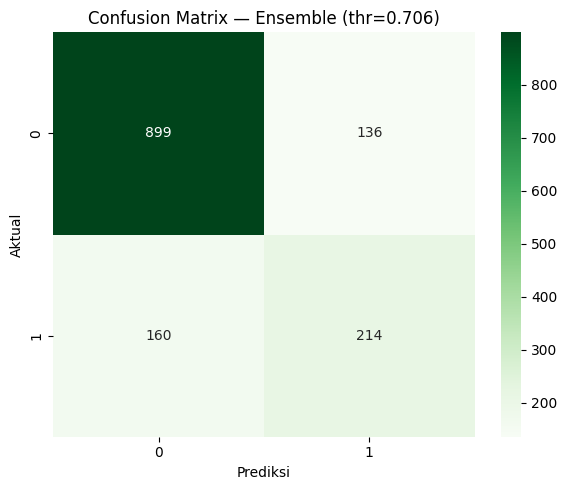


Sampel hasil:


,customerID,Churn_Aktual,Prob_XGB,Prob_RSF,Prob_Ensemble,Prediksi_Ensemble
0,4376-KFVRS,No Churn,0.052740,0.001063,0.037237,No Churn
1,2754-SDJRD,No Churn,0.917025,0.559783,0.809852,Churn
2,9917-KWRBE,No Churn,0.232890,0.038153,0.174469,No Churn
3,0365-GXEZS,No Churn,0.671588,0.503718,0.621227,No Churn
4,9385-NXKDA,No Churn,0.042879,0.005534,0.031675,No Churn
5,4686-UXDML,No Churn,0.858317,0.617814,0.786166,Churn
6,2227-JRSJX,No Churn,0.773054,0.428844,0.669791,No Churn
7,4830-FAXFM,No Churn,0.346757,0.213126,0.306667,No Churn
8,1830-IPXVJ,No Churn,0.027651,0.003003,0.020256,No Churn
9,4690-LLKUA,Churn,0.679228,0.856819,0.732505,Churn


In [ ]:
# ENSEMBLE FUSION: XGB + RSF
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    classification_report, average_precision_score,
)

# ---------- 1. Cari horizon T terbaik — VALIDATION ----------
print("=" * 60)
print("LANGKAH 1: Cari horizon T terbaik (pada VALIDATION)")
print("=" * 60)

surv_fns_val  = rsf_model.predict_survival_function(X_val_rsf)
surv_fns_test = rsf_model.predict_survival_function(X_test_rsf)

best_T, best_auc_rsf = None, -1.0
for T_try in [6, 12, 24, 36, 48]:
    S_T   = np.array([fn(T_try) for fn in surv_fns_val])
    p_rsf = 1.0 - S_T
    if np.ptp(p_rsf) < 1e-6:                       # skip degenerasi
        print(f"  T={T_try:>2} bln → degenerate, skipped")
        continue
    auc_val = roc_auc_score(y_val, p_rsf)
    print(f"  T={T_try:>2} bln → VAL AUC = {auc_val:.4f}")
    if auc_val > best_auc_rsf:
        best_auc_rsf, best_T = auc_val, T_try

if best_T is None:
    raise RuntimeError("Tidak ada horizon T valid di validation.")

print(f"\n→ T terbaik = {best_T} bulan, VAL AUC_RSF = {best_auc_rsf:.4f}")

rsf_prob_val  = 1.0 - np.array([fn(best_T) for fn in surv_fns_val])
rsf_prob_test = 1.0 - np.array([fn(best_T) for fn in surv_fns_test])

# ---------- 2. Cari bobot fusi optimal — VALIDATION ----------
print("\n" + "=" * 60)
print("LANGKAH 2: Cari bobot fusi optimal (pada VALIDATION)")
print("=" * 60)

best_w, best_auc_fuse = None, -1.0
for w in np.arange(0.0, 1.01, 0.05):
    p   = w * xgb_prob_val + (1 - w) * rsf_prob_val
    auc = roc_auc_score(y_val, p)
    if auc > best_auc_fuse:
        best_auc_fuse, best_w = auc, float(w)

print(f"→ Bobot terbaik: w_xgb = {best_w:.2f} → VAL AUC = {best_auc_fuse:.4f}")
if best_w >= 0.999:
    print("  ℹ Fusion ≈ XGB-only (RSF tidak membantu pada horizon ini).")
elif best_w <= 0.001:
    print("  ℹ Fusion ≈ RSF-only (XGB tidak membantu).")
else:
    print(f"  ℹ Keduanya berkontribusi: {best_w:.2f}·XGB + {1-best_w:.2f}·RSF")

ensemble_prob_val  = best_w * xgb_prob_val  + (1 - best_w) * rsf_prob_val
ensemble_prob_test = best_w * xgb_prob    + (1 - best_w) * rsf_prob_test

# ---------- 3. Perbandingan model — VALIDATION ----------
print("\n" + "=" * 60)
print("LANGKAH 3: Perbandingan model pada VALIDATION (ROC-AUC)")
print("=" * 60)
print(f"  XGB only  : {roc_auc_score(y_val, xgb_prob_val):.4f}")
print(f"  RSF only  : {roc_auc_score(y_val, rsf_prob_val):.4f}")
print(f"  Fusion    : {roc_auc_score(y_val, ensemble_prob_val):.4f}")

# ---------- 4. Threshold — dari VALIDATION (best_thr_val) ----------
print("\n" + "=" * 60)
print("LANGKAH 4: Threshold dari VALIDATION")
print("=" * 60)
print(f"→ Threshold = {best_thr_val:.3f}")

# ---------- 5. EVALUASI FINAL — TEST (satu kali, tidak untuk tuning) ----------
ens_pred = (ensemble_prob_test >= best_thr_val).astype(int)

print("\n" + "=" * 60)
print(f"EVALUASI FINAL (threshold = {best_thr_val:.3f})")
print("=" * 60)
print(f"Accuracy  : {accuracy_score(y_test, ens_pred):.4f}")
print(f"Precision : {precision_score(y_test, ens_pred, zero_division=0):.4f}")
print(f"Recall    : {recall_score(y_test, ens_pred, zero_division=0):.4f}")
print(f"F1-score  : {f1_score(y_test, ens_pred, zero_division=0):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, ensemble_prob_test):.4f}")
print(f"PR-AUC    : {average_precision_score(y_test, ensemble_prob_test):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, ens_pred, target_names=["No Churn", "Churn"], zero_division=0
))

cm_ens = confusion_matrix(y_test, ens_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_ens, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Prediksi"); plt.ylabel("Aktual")
plt.title(f"Confusion Matrix — Ensemble (thr={best_thr_val:.3f})")
plt.tight_layout(); plt.show()

# ---------- 6. Tabel hasil ----------
hasil_ensemble = pd.DataFrame({
    "customerID"       : test_df["customerID"].values,
    "Churn_Aktual"     : y_test.map({0: "No Churn", 1: "Churn"}).values,
    "Prob_XGB"         : xgb_prob,
    "Prob_RSF"         : rsf_prob_test,
    "Prob_Ensemble"    : ensemble_prob_test,
    "Prediksi_Ensemble": np.where(ens_pred == 1, "Churn", "No Churn"),
})
print("\nSampel hasil:")
display(hasil_ensemble.head(10))

# Segmentasi K-means

In [ ]:

# Ambil hanya kolom yang dibutuhkan untuk integrasi
data_xgb = hasil_xgb[
    ["customerID", "Probabilitas_Churn", "Churn_Aktual"]
].copy()

data_rsf = hasil_rsf[
    ["customerID", "RSF_Risk_Score"]
].copy()

# Integrasikan berdasarkan customerID
data_integrasi = pd.merge(
    data_xgb,
    data_rsf,
    on="customerID",
    how="inner",
    validate="one_to_one"
)

# Periksa hasil integrasi
print("Jumlah baris hasil integrasi:", len(data_integrasi))
print("Jumlah customer unik:", data_integrasi["customerID"].nunique())
print("\nLima data pertama:")

display(data_integrasi.head(10))

Jumlah baris hasil integrasi: 1409
Jumlah customer unik: 1409

Lima data pertama:


,customerID,Probabilitas_Churn,Churn_Aktual,RSF_Risk_Score
0,4376-KFVRS,0.021587,No Churn,0.171654
1,2754-SDJRD,0.813965,No Churn,47.691825
2,9917-KWRBE,0.070134,No Churn,2.704478
3,0365-GXEZS,0.318870,No Churn,40.873754
4,9385-NXKDA,0.014322,No Churn,0.556004
5,4686-UXDML,0.614674,No Churn,49.995413
6,2227-JRSJX,0.456340,No Churn,33.354605
7,4830-FAXFM,0.107339,No Churn,14.912797
8,1830-IPXVJ,0.010975,No Churn,0.249840
9,4690-LLKUA,0.351239,Churn,109.691216


In [ ]:
from sklearn.preprocessing import StandardScaler

# Fitur yang digunakan untuk segmentasi
fitur_cluster = [
    "Probabilitas_Churn",
    "RSF_Risk_Score"
]

X_cluster = data_integrasi[fitur_cluster].copy()

# Validasi nilai fitur
if X_cluster.isna().any().any():
    raise ValueError("Fitur clustering mengandung missing value.")

if not np.isfinite(X_cluster.to_numpy()).all():
    raise ValueError("Fitur clustering mengandung nilai tak hingga.")

# Standardisasi
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Dimensi fitur:", X_cluster_scaled.shape)
print("Rata-rata fitur setelah standardisasi:",
      X_cluster_scaled.mean(axis=0))
print("Standar deviasi fitur setelah standardisasi:",
      X_cluster_scaled.std(axis=0))

Dimensi fitur: (1409, 2)
Rata-rata fitur setelah standardisasi: [-1.51286601e-17 -1.07161342e-16]
Standar deviasi fitur setelah standardisasi: [1. 1.]


In [ ]:
from sklearn.cluster import KMeans

# Membentuk 3 cluster
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

data_integrasi["Cluster"] = kmeans.fit_predict(
    X_cluster_scaled
)

print("Jumlah pelanggan per cluster:")
display(
    data_integrasi["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah_Pelanggan")
    .to_frame()
)

Jumlah pelanggan per cluster:


,Jumlah_Pelanggan
Cluster,
0,287
1,773
2,349


In [ ]:
# Profil setiap cluster
profil_cluster = (
    data_integrasi
    .groupby("Cluster")
    .agg(
        Jumlah_Pelanggan=("customerID", "nunique"),
        Rata_Probabilitas_Churn=("Probabilitas_Churn", "mean"),
        Rata_RSF_Risk=("RSF_Risk_Score", "mean"),
        Proporsi_Churn_Aktual=(
            "Churn_Aktual",
            lambda x: (x == "Churn").mean()
        )
    )
)

# Standardisasi rata-rata kedua skor antar-cluster
# untuk menyusun urutan risiko
mean_xgb = profil_cluster["Rata_Probabilitas_Churn"]
mean_rsf = profil_cluster["Rata_RSF_Risk"]

std_xgb = mean_xgb.std(ddof=0)
std_rsf = mean_rsf.std(ddof=0)

z_xgb = (
    (mean_xgb - mean_xgb.mean()) / std_xgb
    if std_xgb > 0
    else mean_xgb * 0
)

z_rsf = (
    (mean_rsf - mean_rsf.mean()) / std_rsf
    if std_rsf > 0
    else mean_rsf * 0
)

# Bobot kedua skor dibuat sama
profil_cluster["Skor_Risiko_Rata_Rata"] = (
    z_xgb + z_rsf
) / 2

# Urutkan dari risiko terendah sampai tertinggi
urutan_risiko = (
    profil_cluster["Skor_Risiko_Rata_Rata"]
    .sort_values()
    .index
    .tolist()
)

nama_risiko = {
    urutan_risiko[0]: "Low Risk",
    urutan_risiko[1]: "Medium Risk",
    urutan_risiko[2]: "High Risk"
}

# Tambahkan nama segmen pada setiap pelanggan
data_integrasi["Segmen_Risiko"] = (
    data_integrasi["Cluster"].map(nama_risiko)
)

# Tambahkan nama segmen pada tabel profil
profil_cluster["Segmen_Risiko"] = (
    profil_cluster.index.map(nama_risiko)
)

print("Profil setiap segmen risiko:")
display(
    profil_cluster
    .sort_values("Skor_Risiko_Rata_Rata")
    .round(4)
)

Profil setiap segmen risiko:


,Jumlah_Pelanggan,Rata_Probabilitas_Churn,Rata_RSF_Risk,Proporsi_Churn_Aktual,Skor_Risiko_Rata_Rata,Segmen_Risiko
Cluster,,,,,,
1,773,0.0732,7.6578,0.0841,-1.1993,Low Risk
2,349,0.3782,39.4000,0.3553,-0.0442,Medium Risk
0,287,0.6472,84.2904,0.6446,1.2435,High Risk


In [ ]:
#Evaluasi
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(
    X_cluster_scaled,
    data_integrasi["Cluster"]
)

print(f"Silhouette Score: {sil_score:.4f}")

Silhouette Score: 0.5671


In [ ]:
# Urutan tampilan segmen
urutan_segmen = ["Low Risk", "Medium Risk", "High Risk"]

for segmen in urutan_segmen:
    data_segmen = data_integrasi[
        data_integrasi["Segmen_Risiko"] == segmen
    ].copy()

    print(f"\n{'_'*60}")
    print(f"\nSEGMEN: {segmen}")
    print(f"Jumlah pelanggan: {len(data_segmen)}")
    print(f"{'_'*60}")

    display(data_segmen)


____________________________________________________________

SEGMEN: Low Risk
Jumlah pelanggan: 773
____________________________________________________________


,customerID,Probabilitas_Churn,Churn_Aktual,RSF_Risk_Score,Cluster,Segmen_Risiko
0,4376-KFVRS,0.021587,No Churn,0.171654,1,Low Risk
2,9917-KWRBE,0.070134,No Churn,2.704478,1,Low Risk
4,9385-NXKDA,0.014322,No Churn,0.556004,1,Low Risk
7,4830-FAXFM,0.107339,No Churn,14.912797,1,Low Risk
8,1830-IPXVJ,0.010975,No Churn,0.249840,1,Low Risk
...,...,...,...,...,...,...
1404,5204-HMGYF,0.055540,No Churn,5.872412,1,Low Risk
1405,9950-MTGYX,0.011444,No Churn,0.317480,1,Low Risk
1406,3675-EQOZA,0.118313,No Churn,21.593373,1,Low Risk
1407,3646-ITDGM,0.017150,No Churn,1.182632,1,Low Risk



____________________________________________________________

SEGMEN: Medium Risk
Jumlah pelanggan: 349
____________________________________________________________


,customerID,Probabilitas_Churn,Churn_Aktual,RSF_Risk_Score,Cluster,Segmen_Risiko
3,0365-GXEZS,0.318870,No Churn,40.873754,2,Medium Risk
5,4686-UXDML,0.614674,No Churn,49.995413,2,Medium Risk
6,2227-JRSJX,0.456340,No Churn,33.354605,2,Medium Risk
10,5804-HYIEZ,0.439549,No Churn,14.343806,2,Medium Risk
12,5533-RJFTJ,0.196860,No Churn,50.198060,2,Medium Risk
...,...,...,...,...,...,...
1378,0778-NELLA,0.434473,Churn,43.495657,2,Medium Risk
1379,7495-OOKFY,0.682695,Churn,35.735450,2,Medium Risk
1386,3524-WQDSG,0.471121,No Churn,41.379375,2,Medium Risk
1390,5331-RGMTT,0.513228,No Churn,39.709757,2,Medium Risk



____________________________________________________________

SEGMEN: High Risk
Jumlah pelanggan: 287
____________________________________________________________


,customerID,Probabilitas_Churn,Churn_Aktual,RSF_Risk_Score,Cluster,Segmen_Risiko
1,2754-SDJRD,0.813965,No Churn,47.691825,0,High Risk
9,4690-LLKUA,0.351239,Churn,109.691216,0,High Risk
13,4706-AXVKM,0.688157,Churn,65.119777,0,High Risk
17,1379-FRVEB,0.583211,No Churn,63.042662,0,High Risk
20,7235-NXZCP,0.710395,Churn,76.308256,0,High Risk
...,...,...,...,...,...,...
1388,8601-QACRS,0.450439,Churn,75.625110,0,High Risk
1393,0679-IDSTG,0.852378,Churn,92.676363,0,High Risk
1395,2101-RANCD,0.371781,No Churn,102.633184,0,High Risk
1396,4029-HPFVY,0.569669,No Churn,78.185610,0,High Risk


In [ ]:
profil_detail = (
    data_integrasi
    .groupby(["Cluster", "Segmen_Risiko"])
    .agg(
        Jumlah_Pelanggan=("customerID", "nunique"),
        Rata_Rata_Probabilitas_Churn=("Probabilitas_Churn", "mean"),
        Min_Probabilitas_Churn=("Probabilitas_Churn", "min"),
        Max_Probabilitas_Churn=("Probabilitas_Churn", "max"),
        Rata_Rata_RSF_Risk=("RSF_Risk_Score", "mean"),
        Churn_Aktual=("Churn_Aktual",
                      lambda x: (x == "Churn").sum()),
        Non_Churn_Aktual=("Churn_Aktual",
                          lambda x: (x == "No Churn").sum())
    )
    .reset_index()
)

profil_detail["Persentase_Churn_Aktual"] = (
    profil_detail["Churn_Aktual"]
    / profil_detail["Jumlah_Pelanggan"] * 100
).round(2)

display(profil_detail.round(4))

,Cluster,Segmen_Risiko,Jumlah_Pelanggan,Rata_Rata_Probabilitas_Churn,Min_Probabilitas_Churn,Max_Probabilitas_Churn,Rata_Rata_RSF_Risk,Churn_Aktual,Non_Churn_Aktual,Persentase_Churn_Aktual
0,0,High Risk,287,0.6472,0.2925,0.9239,84.2904,185,102,64.46
1,1,Low Risk,773,0.0732,0.0048,0.3243,7.6578,65,708,8.41
2,2,Medium Risk,349,0.3782,0.1282,0.7415,39.4000,124,225,35.53


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Confusion Matrix dengan Threshold yang Disesuaikan (misal: 0.4)
threshold = 0.4
y_pred_custom = (xgb_prob >= threshold).astype(int)
cm = confusion_matrix(y_test, y_pred_custom)
print("Confusion Matrix (Threshold 0.4):")
print(cm)

# 2. Gain / Lift Table sederhana
eval_df = pd.DataFrame({'Actual': y_test, 'Prob': xgb_prob})
eval_df = eval_df.sort_values(by='Prob', ascending=False).reset_index(drop=True)
eval_df['Decile'] = pd.qcut(eval_df.index, 10, labels=False) + 1

lift_table = eval_df.groupby('Decile').agg(
    Total_Customers=('Actual', 'count'),
    Actual_Churn=('Actual', 'sum')
).reset_index()

lift_table['Cumulative_Churn'] = lift_table['Actual_Churn'].cumsum()
lift_table['Gain_%'] = (lift_table['Cumulative_Churn'] / lift_table['Actual_Churn'].sum()) * 100
print("\nLift & Gain Table per Decile:")
print(lift_table)

Confusion Matrix (Threshold 0.4):
[[620 415]
 [ 38 336]]

Lift & Gain Table per Decile:
   Decile  Total_Customers  Actual_Churn  Cumulative_Churn      Gain_%
0       1              141           108               108   28.877005
1       2              141            80               188   50.267380
2       3              141            64               252   67.379679
3       4              141            39               291   77.807487
4       5              141            36               327   87.433155
5       6              140            24               351   93.850267
6       7              141             9               360   96.256684
7       8              141             9               369   98.663102
8       9              141             4               373   99.732620
9      10              141             1               374  100.000000


Jumlah Pelanggan per Kluster Risiko:
Cluster
1    773
2    349
0    287
Name: count, dtype: int64

Ringkasan Rata-Rata Skor per Kluster:
         Probabilitas_Churn  RSF_Risk_Score
Cluster                                    
0                  0.647233       84.290411
1                  0.073175        7.657808
2                  0.378156       39.400025


/tmp/ipykernel_1865/3424771526.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data_integrasi, x='Cluster', palette='Set2')


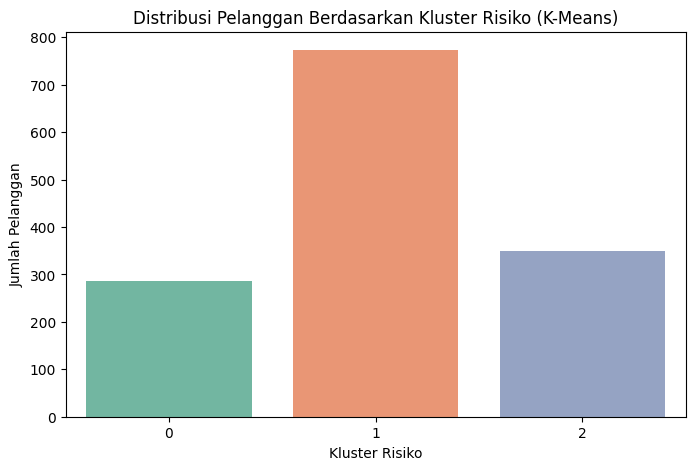

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan Anda sudah menjalankan sel K-Means hingga menghasilkan label kluster,
# misal: data_integrasi['Cluster'] = kmeans.fit_predict(X_cluster_scaled)

# 1. Melihat jumlah anggota di setiap kluster risiko
print("Jumlah Pelanggan per Kluster Risiko:")
print(data_integrasi['Cluster'].value_counts())

# 2. Rata-rata skor fitur per kluster (Probabilitas Churn & RSF Risk Score)
cluster_summary = data_integrasi.groupby('Cluster')[['Probabilitas_Churn', 'RSF_Risk_Score']].mean()
print("\nRingkasan Rata-Rata Skor per Kluster:")
print(cluster_summary)

# 3. Visualisasi distribusi kluster
plt.figure(figsize=(8, 5))
sns.countplot(data=data_integrasi, x='Cluster', palette='Set2')
plt.title('Distribusi Pelanggan Berdasarkan Kluster Risiko (K-Means)')
plt.xlabel('Kluster Risiko')
plt.ylabel('Jumlah Pelanggan')
plt.show()

--- PROFILING KARAKTERISTIK KLUSTER RISIKO ---


,Cluster,Jumlah_Pelanggan,Rata_Rata_Probabilitas_Churn,Rata_Rata_Risk_Score
0,0,287,0.647233,84.290411
1,1,773,0.073175,7.657808
2,2,349,0.378156,39.400025


/tmp/ipykernel_1865/638749084.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cluster_profile, x='Cluster', y='Jumlah_Pelanggan', palette='viridis')


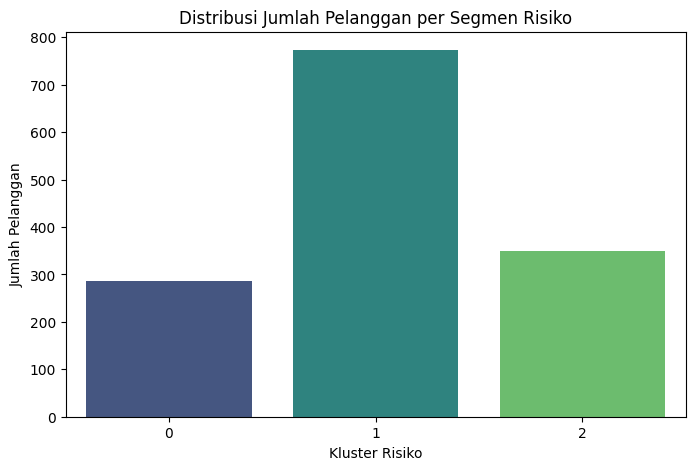

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pastikan data_integrasi sudah memiliki label kluster dari K-Means
# (Misalnya kolom klusternya bernama 'Cluster')
df_cluster = data_integrasi.copy()

# Jika label kluster disimpan di variabel terpisah bernama 'clusters', gabungkan dulu:
# df_cluster['Cluster'] = clusters

# 2. Analisis Rata-rata Fitur per Kluster Risiko (menggunakan kolom yang sesuai dengan kode Anda)
cluster_profile = df_cluster.groupby('Cluster').agg(
    Jumlah_Pelanggan=('customerID', 'count'),
    Rata_Rata_Probabilitas_Churn=('Probabilitas_Churn', 'mean'),
    Rata_Rata_Risk_Score=('RSF_Risk_Score', 'mean')
).reset_index()

print("--- PROFILING KARAKTERISTIK KLUSTER RISIKO ---")
display(cluster_profile)

# 3. Visualisasi Sederhana Perbandingan Kluster
plt.figure(figsize=(8, 5))
sns.barplot(data=cluster_profile, x='Cluster', y='Jumlah_Pelanggan', palette='viridis')
plt.title('Distribusi Jumlah Pelanggan per Segmen Risiko')
plt.xlabel('Kluster Risiko')
plt.ylabel('Jumlah Pelanggan')
plt.show()